# Fitting commuting generators to the CA1 place cells (Fig. 4, App. K)

Fits the exponential map to the rate maps of every spatially tuned CA1 unit of one rat, so
that one model describes one animal's place code, and writes
`data/ca1_fit_one_animal_si0.50.npz`, which `fitting_figures` and
`fitted_similarity_structure` read.

Three choices define the population (App. K).

1. *One animal.* Rat 25398, which has the most units.
2. *Every spatially tuned unit.* The selection of `ca1_population`: nested duplicates dropped,
   mean rate between 1 and 10 Hz, spatial information of at least 0.5 bits per spike.
   Single-field, multi-field, border-like and unstable units enter alike, with no field
   criterion. Few units were recorded in any one session, so the population is pooled over
   the rat's sessions, and its population vectors were never observed together.
3. *Cross-day repeats removed.* Tetrodes stay in place across days, so the same cell can enter
   the pool once per session. Units on the same tetrode recorded on different days whose rate
   maps correlate above `REPEAT_CORRELATION` are treated as one cell. The one with the highest
   spatial information represents it.

The model, the fit and the two evaluations are those of `fit_grid_cells`: the reconstruction
of the arena from the recorded population vector at its center, and the extrapolation from a
fit to the central three quarters of the arena side to the part no training step touched. The
maps are scaled by one constant so that their maximum equals that of the grid-cell file, and
the fit parameters are the same.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.sparse.csgraph import connected_components

from expmap.fitting import CommutingGeneratorFit

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT / "notebooks" / "experimental_data"))
from ca1 import load_events, place_fields, population_ratemaps, select_units  # noqa: E402
from galleries import gallery  # noqa: E402

EVENTS = REPO_ROOT / "data" / "ca1_events.npz"
GRID_DATA = REPO_ROOT / "data" / "gc_ratmaps.npy"
OUTPUT = REPO_ROOT / "data" / "ca1_fit_one_animal_si0.50.npz"

# The population.
ANIMAL = "25398"
RATE_RANGE = (1.0, 10.0)  # Hz, mean over the session, the source paper's criterion
INFO_THRESHOLD = 0.5  # bits per spike
REPEAT_CORRELATION = 0.9  # same tetrode, different day, rate maps correlated above this: one cell

# Rate maps and field delineation, as in ca1_population.
N_BINS = 32
MAP_SIGMA = 1.0
POSITION_SIGMA = 3.0
SPEED_RANGE = (6.0, 60.0)
FIELD_THRESHOLD = 0.2
FIELD_MIN_BINS = 9

# Fit parameters, as in fit_grid_cells.
N_STEPS = 20000
BATCH_SIZE = 32
MAX_STEP = 2
LR = 1e-3
WAVEVECTOR_LR = 1e-2
ARENA_SIZE = 1.0
SEED = 0

# The extrapolation fit sees the central square of this fraction of the arena side.
FITTED_FRACTION = 0.75
CHANCE_DRAWS = 200

## Population

The rate maps and spatial information of every unit of the rat that passes the first two
selection steps of `ca1_population`, nested duplicates dropped and mean rate in range. The
cross-day repeats are linked over all of these units, and the information threshold is applied
after.


In [2]:
sessions, units = load_events(EVENTS)
rate_passing = select_units(units, RATE_RANGE)
rate_passing = rate_passing[[sessions[units[i].session].animal == ANIMAL for i in rate_passing]]
rates, _, information = population_ratemaps(sessions, units, rate_passing, N_BINS, MAP_SIGMA, POSITION_SIGMA, SPEED_RANGE)
date = np.array([sessions[units[i].session].date for i in rate_passing])
tetrode = np.array([units[i].tetrode for i in rate_passing])
cluster = np.array([units[i].cluster for i in rate_passing])
n_fields = np.array([place_fields(r, FIELD_THRESHOLD, FIELD_MIN_BINS).max() for r in rates])
del sessions, units

tuned = information >= INFO_THRESHOLD
print(f"rat {ANIMAL}: {len(rates)} units in the rate range, {tuned.sum()} with spatial information >= {INFO_THRESHOLD} bits/spike")

rat 25398: 151 units in the rate range, 107 with spatial information >= 0.5 bits/spike


## Cross-day repeats

Two units are linked when they sit on the same tetrode, were recorded on different days and
their rate maps correlate above `REPEAT_CORRELATION`. Linked units form a group, and the unit
with the highest spatial information represents it. As a reference for false positives, the
same test is applied to pairs that cannot be the same cell, on another tetrode or on the same
day. The groups are shown below, one row per group.


pairs above r = 0.9: 5 of 2808 same-tetrode other-day pairs, 1 of 8517 other pairs
population: 103 of the 107 tuned units after removing repeats, over 37 sessions, 47 with one field and 56 with several


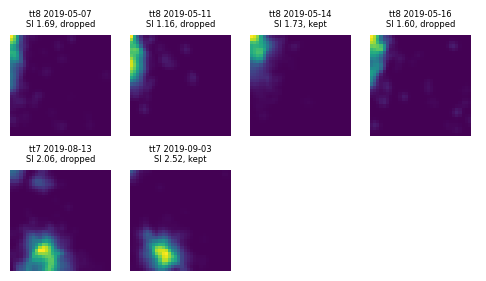

In [3]:
C = np.corrcoef(rates.reshape(len(rates), -1))
candidate = (tetrode[:, None] == tetrode[None]) & (date[:, None] != date[None])
_, group = connected_components((C > REPEAT_CORRELATION) & candidate, directed=False)

distinct = np.zeros(len(rates), bool)
for g in np.unique(group):
    members = np.flatnonzero(group == g)
    distinct[members[information[members].argmax()]] = True

upper = np.triu(np.ones_like(C, bool), 1)
other = ~candidate & ~np.eye(len(rates), dtype=bool)
print(
    f"pairs above r = {REPEAT_CORRELATION}: {(C[candidate & upper] > REPEAT_CORRELATION).sum()} of "
    f"{(candidate & upper).sum()} same-tetrode other-day pairs, "
    f"{(C[other & upper] > REPEAT_CORRELATION).sum()} of {(other & upper).sum()} other pairs"
)

selected = np.flatnonzero(distinct & tuned)
print(
    f"population: {len(selected)} of the {tuned.sum()} tuned units after removing repeats, over {len(set(date[selected]))} sessions, "
    f"{(n_fields[selected] == 1).sum()} with one field and {(n_fields[selected] > 1).sum()} with several"
)

repeated = [np.flatnonzero(group == g) for g in np.unique(group) if (group == g).sum() > 1]
n_cols = max(len(members) for members in repeated)
fig, axs = plt.subplots(len(repeated), n_cols, figsize=(n_cols * 1.2, len(repeated) * 1.35), layout="constrained", squeeze=False)
for ax in axs.ravel():
    ax.axis("off")
for row, members in enumerate(repeated):
    for ax, k in zip(axs[row], members[np.argsort(date[members])]):
        ax.imshow(rates[k].T / rates[k].max(), origin="lower", cmap="viridis", vmin=0, vmax=1)
        ax.set_title(f"tt{tetrode[k]} {date[k]}\nSI {information[k]:.2f}, {'kept' if distinct[k] else 'dropped'}", fontsize=6)

## Fit


103 units, loss 3.827e-05 -> 2.067e-05


Text(0, 0.5, 'loss')

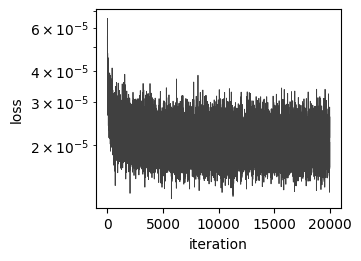

In [4]:
# Scaled to the maximum of the grid-cell maps, so that the two fits see the same range.
scale = float(np.load(GRID_DATA).max()) / rates[selected].max()
experimental = (rates[selected] * scale).astype("float32")
ratemaps = torch.tensor(np.transpose(experimental, (1, 2, 0)))  # (bins_x, bins_y, n_units), a bin index returns a population vector
N_UNITS = len(experimental)

fit = CommutingGeneratorFit(n_units=N_UNITS, lr=LR, wavevector_lr=WAVEVECTOR_LR, seed=SEED)
loss_history = fit.fit(ratemaps, n_steps=N_STEPS, batch_size=BATCH_SIZE, max_step=MAX_STEP, arena_size=ARENA_SIZE, progress=False)
print(f"{N_UNITS} units, loss {np.mean(loss_history[:100]):.3e} -> {np.mean(loss_history[-100:]):.3e}")

fig, ax = plt.subplots(figsize=(3.5, 2.5), layout="constrained")
ax.semilogy(loss_history, "k", linewidth=0.6, alpha=0.75)
ax.set_xlabel("iteration")
ax.set_ylabel("loss")

## Reconstruction

The recorded population vector at the arena center is transported to every bin and the
generated map of each unit is compared with its recorded map through the Pearson correlation
over bins, as in `fit_grid_cells`. The median is also given for the units with one field and
for those with several.


correlation, model vs data: median 0.77, 10th to 90th percentile 0.65 to 0.88
  one field: median 0.82 (47 units); several: 0.75 (56 units)


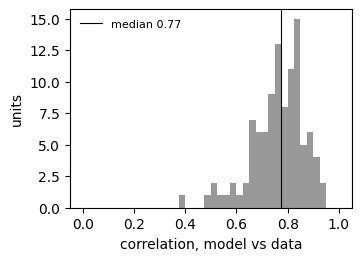

In [5]:
centre = ratemaps[N_BINS // 2, N_BINS // 2]
generated = fit.generate(centre, n_bins=N_BINS, extent=1.0, arena_size=ARENA_SIZE).numpy()
correlation = np.array([np.corrcoef(g.ravel(), e.ravel())[0, 1] for g, e in zip(generated, experimental)])
single = n_fields[selected] == 1
print(f"correlation, model vs data: median {np.median(correlation):.2f}, 10th to 90th percentile {np.percentile(correlation, 10):.2f} to {np.percentile(correlation, 90):.2f}")
print(f"  one field: median {np.median(correlation[single]):.2f} ({single.sum()} units); several: {np.median(correlation[~single]):.2f} ({(~single).sum()} units)")

fig, ax = plt.subplots(figsize=(3.5, 2.5), layout="constrained")
ax.hist(correlation, bins=np.linspace(0, 1, 41), color="0.6")
ax.axvline(np.median(correlation), color="k", linewidth=0.8, label=f"median {np.median(correlation):.2f}")
ax.set_xlabel("correlation, model vs data")
ax.set_ylabel("units")
ax.legend(frameon=False, fontsize=8, loc="upper left")

### Data and model side by side

Units sorted by correlation, best to worst, evenly sampled. Rows alternate data and model, and
each pair shares the unit's own scale.


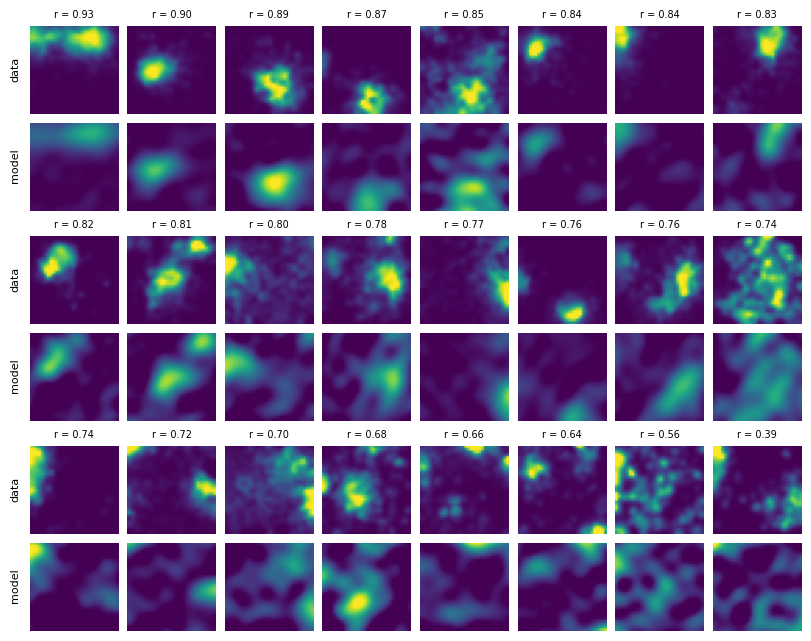

In [6]:
fig = gallery(experimental, generated, correlation, n_show=24)

## Extrapolation beyond the fitted square

The model is fitted anew to the central square spanning `FITTED_FRACTION` of the arena side,
and the whole arena is generated from its center at the same bin size. The outer bins are then
compared with data no training step touched. Two chance levels, each the mean over
`CHANCE_DRAWS` draws of the median correlation: the untrained part of each recorded map with its bins
shuffled, and each unit's prediction against the data of a random other unit. The units whose
recorded map peaks in the untrained part are also scored on their own.


fitted square: bins 4 to 27 of 32, 44% of the arena untrained
correlation inside the fitted square: median 0.81
correlation on the untrained part: median 0.61, 10th to 90th percentile 0.28 to 0.84
chance on the untrained part: bins shuffled -0.00, units shuffled -0.02
units whose recorded map peaks in the untrained part: 49 of 103, median 0.62


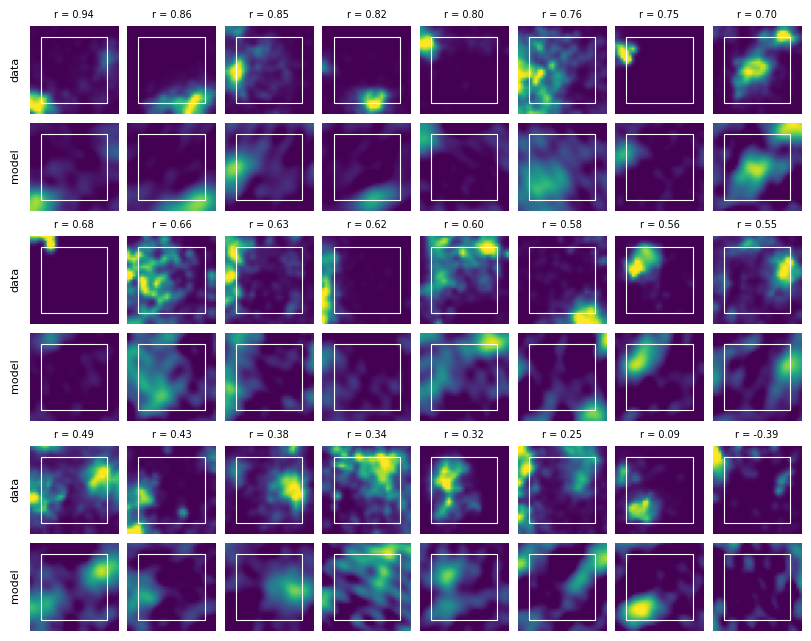

In [7]:
lo = round(N_BINS * (1 - FITTED_FRACTION) / 2)
hi = N_BINS - lo
inner = np.zeros((N_BINS, N_BINS), bool)
inner[lo:hi, lo:hi] = True
crop = ratemaps[lo:hi, lo:hi]

# The crop spans [-FITTED_FRACTION, FITTED_FRACTION] of the arena, so its bins are the arena's bins.
crop_fit = CommutingGeneratorFit(n_units=N_UNITS, lr=LR, wavevector_lr=WAVEVECTOR_LR, seed=SEED)
crop_loss = crop_fit.fit(crop, n_steps=N_STEPS, batch_size=BATCH_SIZE, max_step=MAX_STEP, arena_size=FITTED_FRACTION * ARENA_SIZE, progress=False)
extrapolated = crop_fit.generate(crop[(hi - lo) // 2, (hi - lo) // 2], n_bins=N_BINS, extent=1.0, arena_size=ARENA_SIZE).numpy()


def correlation_over(model, data, where):
    return np.array([np.corrcoef(g[where], e[where])[0, 1] for g, e in zip(model, data)])


inner_corr = correlation_over(extrapolated, experimental, inner)
outer_corr = correlation_over(extrapolated, experimental, ~inner)
rng = np.random.default_rng(SEED)
unit_chance = np.mean([np.median(correlation_over(extrapolated[rng.permutation(N_UNITS)], experimental, ~inner)) for _ in range(CHANCE_DRAWS)])
bin_chance = np.mean(
    [np.median([np.corrcoef(g[~inner], rng.permutation(e[~inner]))[0, 1] for g, e in zip(extrapolated, experimental)]) for _ in range(CHANCE_DRAWS)]
)
peak = np.array([np.unravel_index(m.argmax(), m.shape) for m in experimental])
peak_untrained = ~inner[peak[:, 0], peak[:, 1]]

print(f"fitted square: bins {lo} to {hi - 1} of {N_BINS}, {1 - FITTED_FRACTION**2:.0%} of the arena untrained")
print(f"correlation inside the fitted square: median {np.median(inner_corr):.2f}")
print(f"correlation on the untrained part: median {np.median(outer_corr):.2f}, 10th to 90th percentile {np.percentile(outer_corr, 10):.2f} to {np.percentile(outer_corr, 90):.2f}")
print(f"chance on the untrained part: bins shuffled {bin_chance:.2f}, units shuffled {unit_chance:.2f}")
print(f"units whose recorded map peaks in the untrained part: {peak_untrained.sum()} of {N_UNITS}, median {np.median(outer_corr[peak_untrained]):.2f}")

fig = gallery(experimental, extrapolated, outer_corr, box=(lo, hi), n_show=24)

## Save

The layout of `data/gc_fit_commuting.npz`, with the scale, the selection parameters and the
provenance of every unit added.


In [8]:
np.savez_compressed(
    OUTPUT,
    Gx=fit.Gx.detach().numpy(),
    Gy=fit.Gy.detach().numpy(),
    R=fit.R.detach().numpy(),
    wavevectors=fit.wavevectors.detach().numpy(),
    loss_history=np.array(loss_history),
    experimental=experimental,
    generated=generated,
    correlation=correlation,
    seed=SEED,
    n_steps=N_STEPS,
    fitted_fraction=FITTED_FRACTION,
    inner=inner,
    extrapolated=extrapolated,
    crop_Gx=crop_fit.Gx.detach().numpy(),
    crop_Gy=crop_fit.Gy.detach().numpy(),
    crop_loss_history=np.array(crop_loss),
    outer_correlation=outer_corr,
    outer_correlation_chance=unit_chance,
    scale=scale,
    animal=ANIMAL,
    info_threshold=INFO_THRESHOLD,
    repeat_correlation=REPEAT_CORRELATION,
    information=information[selected],
    n_fields=n_fields[selected],
    date=date[selected],
    tetrode=tetrode[selected],
    cluster=cluster[selected],
)
print(f"saved {OUTPUT.name}")

saved ca1_fit_one_animal_si0.50.npz
